In [ ]:
%pip -q install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

# Fetch the real UCI Student Performance dataset
student_data = fetch_ucirepo(id=320)

# Separate input features and prediction target
X = student_data.data.features
y = student_data.data.targets

# Inspect the dataset
print("Dataset:", student_data.metadata.name)
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFirst five feature rows:")
print(X.head())

print("\nTarget columns:")
print(y.columns.tolist())

Dataset: Student Performance
Feature shape: (649, 30)
Target shape: (649, 3)

First five feature rows:
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  higher internet  romantic  famrel  freetime goout Dalc Walc health absences  
0    yes       no        no       4         3     4    1    1      3        4  
1    yes      yes        no       5         3     3    1    1      3        2  
2    yes      yes        no       4         3     2    2    3      3        6  
3    yes      yes       yes       3         2     2    1    1      5        0  
4    yes  

In [ ]:
# Check column data types
print("DATA TYPES")
print(X.dtypes)

# Check missing values
print("\nMISSING VALUES")
print(X.isnull().sum().sort_values(ascending=False).head(10))

# Check duplicate input rows
print("\nDUPLICATE INPUT ROWS:", X.duplicated().sum())

# Understand the final-grade target
print("\nFINAL GRADE SUMMARY")
print(y["G3"].describe())

# Count each final-grade value
print("\nGRADE COUNTS")
print(y["G3"].value_counts().sort_index())

DATA TYPES
school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences       int64
dtype: object

MISSING VALUES
school     0
sex        0
age        0
address    0
famsize    0
Pstatus    0
Medu       0
Fedu       0
Mjob       0
Fjob       0
dtype: int64

DUPLICATE INPUT ROWS: 0

FINAL GRADE SUMMARY
count    649.000000
mean      11.906009
std        3.230656
min        0.000000
25%       10.000000
50%       12.000000
75%       14.000000


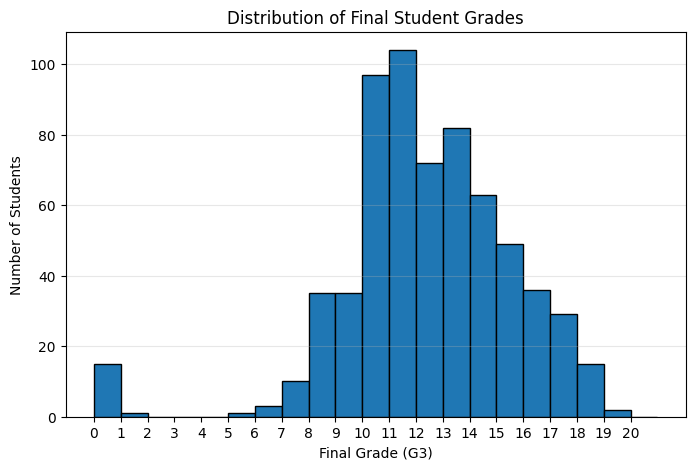

In [ ]:
import matplotlib.pyplot as plt

# Create a histogram of final grades
plt.figure(figsize=(8, 5))
plt.hist(y["G3"], bins=range(0, 22), edgecolor="black")

plt.title("Distribution of Final Student Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.xticks(range(0, 21))
plt.grid(axis="y", alpha=0.3)

plt.show()

In [ ]:
# Check missing values across all features and targets
print("Missing values in features:", X.isnull().sum().sum())
print("Missing values in targets:", y.isnull().sum().sum())

# Confirm the final grade is within the expected range
print("G3 minimum:", y["G3"].min())
print("G3 maximum:", y["G3"].max())

Missing values in features: 0
Missing values in targets: 0
G3 minimum: 0
G3 maximum: 19


In [ ]:
from sklearn.model_selection import train_test_split

# Scenario A: Include previous grades as input features
X_with_grades = X.join(y[["G1", "G2"]])

# Scenario B: Exclude previous grades
X_without_grades = X.copy()

# Select the final grade as our target
y_final = y["G3"]

# Split Scenario A into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_with_grades,
    y_final,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training features:", X_train.shape[1])
print("Test features:", X_test.shape[1])
print("Target name:", y_train.name)

Training records: 519
Testing records: 130
Training features: 32
Test features: 32
Target name: G3


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns

# Prepare numerical features
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Prepare categorical features
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

# Create a baseline model
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

print("Baseline MAE:", mean_absolute_error(
    y_test, baseline_predictions
))
print("Baseline R²:", r2_score(
    y_test, baseline_predictions
))

# Create the Linear Regression pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Train the model
model.fit(X_train, y_train)

# Evaluate on held-out test data
predictions = model.predict(X_test)

print("\nLinear Regression MAE:",
      mean_absolute_error(y_test, predictions))
print("Linear Regression R²:",
      r2_score(y_test, predictions))

Baseline MAE: 2.3946050096339113
Baseline R²: -0.032159804579835916

Linear Regression MAE: 0.7650597682758263
Linear Regression R²: 0.8486513286537314


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Split the data without previous grades
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_without_grades,
    y_final,
    test_size=0.2,
    random_state=42
)

# Identify feature types
numeric_b = X_train_b.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_b = X_train_b.select_dtypes(
    include=["object", "category"]
).columns

# Build preprocessing pipeline
preprocessor_b = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric_b),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_b)
])

# Establish a baseline
baseline_b = DummyRegressor(strategy="mean")
baseline_b.fit(X_train_b, y_train_b)
pred_baseline_b = baseline_b.predict(X_test_b)

# Train Linear Regression
model_b = Pipeline([
    ("preprocessor", preprocessor_b),
    ("regressor", LinearRegression())
])
model_b.fit(X_train_b, y_train_b)
pred_b = model_b.predict(X_test_b)

# Compare results
print("Baseline MAE:", mean_absolute_error(y_test_b, pred_baseline_b))
print("Baseline R²:", r2_score(y_test_b, pred_baseline_b))

print("\nLinear Regression MAE:", mean_absolute_error(y_test_b, pred_b))
print("Linear Regression R²:", r2_score(y_test_b, pred_b))

Baseline MAE: 2.3946050096339113
Baseline R²: -0.032159804579835916

Linear Regression MAE: 2.156382187028527
Linear Regression R²: 0.1601699196431835


In [ ]:
import pandas as pd

results = pd.DataFrame({
    "Model": ["Mean Baseline", "Linear Regression"],
    "MAE": [
        mean_absolute_error(y_test_b, pred_baseline_b),
        mean_absolute_error(y_test_b, pred_b)
    ],
    "R2": [
        r2_score(y_test_b, pred_baseline_b),
        r2_score(y_test_b, pred_b)
    ]
})

print(results.round(3))

               Model    MAE     R2
0      Mean Baseline  2.395 -0.032
1  Linear Regression  2.156  0.160


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, r2_score

# Build the Random Forest pipeline
rf_model = Pipeline([
    ("preprocessor", preprocessor_b),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])

# Train using training data only
rf_model.fit(X_train_b, y_train_b)

# Evaluate on the same held-out test set
rf_predictions = rf_model.predict(X_test_b)

print("Random Forest MAE:",
      mean_absolute_error(y_test_b, rf_predictions))

print("Random Forest R²:",
      r2_score(y_test_b, rf_predictions))

Random Forest MAE: 2.0396153846153844
Random Forest R²: 0.1879336120482512


In [ ]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Mean Baseline",
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        mean_absolute_error(y_test_b, pred_baseline_b),
        mean_absolute_error(y_test_b, pred_b),
        mean_absolute_error(y_test_b, rf_predictions)
    ],
    "R2": [
        r2_score(y_test_b, pred_baseline_b),
        r2_score(y_test_b, pred_b),
        r2_score(y_test_b, rf_predictions)
    ]
})

comparison = comparison.sort_values("MAE")
print(comparison.round(3))

               Model    MAE     R2
2      Random Forest  2.040  0.188
1  Linear Regression  2.156  0.160
0      Mean Baseline  2.395 -0.032
